In [62]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Conceptual Model Combining Text + Transaction Metadata

Using best performing model for the text data (random forest)

In [80]:
# importing/taking a look at the data
concept_df = pd.read_csv('/content/drive/MyDrive/Senior Year/Spring 2026/DSA 412/banking-transaction-categorization-dataset.csv')

display(concept_df.head())

concept_df.info()

display(concept_df.describe(include='all'))

,transaction_id,account_id,transaction_date,transaction_time,amount,currency,merchant_name,merchant_category_code,transaction_description,category,subcategory,transaction_type,is_recurring,recurring_frequency,balance_after_transaction,location_city,location_state,location_country
0,TXN000001,ACC10001,2024-04-03,10:19:32,-112.79,USD,Whole Foods Market,5411.0,Whole Foods Market San Francisco CA,Groceries,Supermarkets,debit,False,NaN,1958.21,San Francisco,CA,USA
1,TXN000002,ACC10002,2024-03-31,08:38:09,2320.00,USD,ACME Payroll,0.0,ACME Payroll Direct Deposit,Salary,NaN,credit,True,monthly,4103.55,NaN,NaN,USA
2,TXN000003,ACC10003,2024-04-04,12:12:44,-46.00,USD,Uber,4121.0,Uber trip CA3245,Transportation,Taxi/Rideshare,debit,False,NaN,320.12,Los Angeles,CA,USA
3,TXN000004,ACC10001,2024-04-05,16:03:23,-1200.00,USD,Sunset Villas,6513.0,Sunset Villas Monthly Rent,Rent,Apartment,payment,True,monthly,758.21,Oakland,CA,USA
4,TXN000005,ACC10004,2024-04-01,19:21:07,-85.45,USD,Comcast,4899.0,Comcast Internet Bill,Utilities,Internet,debit,True,monthly,1420.40,Seattle,WA,USA


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             200 non-null    object 
 1   account_id                 200 non-null    object 
 2   transaction_date           200 non-null    object 
 3   transaction_time           189 non-null    object 
 4   amount                     200 non-null    float64
 5   currency                   200 non-null    object 
 6   merchant_name              162 non-null    object 
 7   merchant_category_code     192 non-null    float64
 8   transaction_description    200 non-null    object 
 9   category                   200 non-null    object 
 10  subcategory                178 non-null    object 
 11  transaction_type           200 non-null    object 
 12  is_recurring               200 non-null    bool   
 13  recurring_frequency        53 non-null     object 

,transaction_id,account_id,transaction_date,transaction_time,amount,currency,merchant_name,merchant_category_code,transaction_description,category,subcategory,transaction_type,is_recurring,recurring_frequency,balance_after_transaction,location_city,location_state,location_country
count,200,200,200,189,200.000000,200,162,192.000000,200,200,178,200,200,53,2.000000e+02,135,110,200
unique,200,70,93,185,NaN,6,69,NaN,173,15,66,6,2,1,NaN,20,10,7
top,TXN000001,ACC40002,2024-04-03,12:12:12,NaN,USD,PG&E,NaN,ATM Withdrawal Fee,Transportation,Supermarkets,debit,False,monthly,NaN,San Francisco,CA,USA
freq,1,10,7,3,NaN,164,11,NaN,5,25,19,95,147,53,NaN,18,39,163
mean,NaN,NaN,NaN,NaN,5549.797550,NaN,NaN,4753.338542,NaN,NaN,NaN,NaN,NaN,NaN,1.816368e+04,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,72296.498102,NaN,NaN,2222.874936,NaN,NaN,NaN,NaN,NaN,NaN,1.354266e+05,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,-78000.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,-2.493750e+03,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,-108.230000,NaN,NaN,4413.500000,NaN,NaN,NaN,NaN,NaN,NaN,7.285975e+02,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,-45.995000,NaN,NaN,5411.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.221520e+03,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,-1.442500,NaN,NaN,6011.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.210293e+03,NaN,NaN,NaN


In [81]:
#checking for missing values
concept_df.isna().sum()

,0
transaction_id,0
account_id,0
transaction_date,0
transaction_time,11
amount,0
currency,0
merchant_name,38
merchant_category_code,8
transaction_description,0
category,0


### Preprocessing Data

In [82]:
#one hot encoding to deal with missing values
from sklearn.preprocessing import OneHotEncoder

# Making a copy of dataframe
concept_df_processed = concept_df.copy()

# Fill NaN values in 'recurring_frequency' with 'Non-Recurring'
concept_df_processed['recurring_frequency'] = concept_df_processed['recurring_frequency'].fillna('Non-Recurring')

# Initializing OneHotEncoder
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fitting and transforming the 'recurring_frequency' column
recurring_freq_encoded = ohe.fit_transform(concept_df_processed[['recurring_frequency']])

# Creating DataFrame from encoded features
recurring_freq_df = pd.DataFrame(recurring_freq_encoded, columns=ohe.get_feature_names_out(['recurring_frequency']))

# joining new columns with the original DataFrame
concept_df_processed = pd.concat([concept_df_processed.reset_index(drop=True), recurring_freq_df], axis=1)

# Dropping original 'recurring_frequency' column
concept_df_processed = concept_df_processed.drop('recurring_frequency', axis=1)

display(concept_df_processed.head())

,transaction_id,account_id,transaction_date,transaction_time,amount,currency,merchant_name,merchant_category_code,transaction_description,category,subcategory,transaction_type,is_recurring,balance_after_transaction,location_city,location_state,location_country,recurring_frequency_Non-Recurring,recurring_frequency_monthly
0,TXN000001,ACC10001,2024-04-03,10:19:32,-112.79,USD,Whole Foods Market,5411.0,Whole Foods Market San Francisco CA,Groceries,Supermarkets,debit,False,1958.21,San Francisco,CA,USA,1.0,0.0
1,TXN000002,ACC10002,2024-03-31,08:38:09,2320.00,USD,ACME Payroll,0.0,ACME Payroll Direct Deposit,Salary,NaN,credit,True,4103.55,NaN,NaN,USA,0.0,1.0
2,TXN000003,ACC10003,2024-04-04,12:12:44,-46.00,USD,Uber,4121.0,Uber trip CA3245,Transportation,Taxi/Rideshare,debit,False,320.12,Los Angeles,CA,USA,1.0,0.0
3,TXN000004,ACC10001,2024-04-05,16:03:23,-1200.00,USD,Sunset Villas,6513.0,Sunset Villas Monthly Rent,Rent,Apartment,payment,True,758.21,Oakland,CA,USA,0.0,1.0
4,TXN000005,ACC10004,2024-04-01,19:21:07,-85.45,USD,Comcast,4899.0,Comcast Internet Bill,Utilities,Internet,debit,True,1420.40,Seattle,WA,USA,0.0,1.0


One hot encoded subcategory and merchant name due to small dataset size (wanted to keep as many records as I can, and could afford to one hot encode without excessive dimensionality)

In [83]:
# Filling NaN values in 'subcategory' with 'Unknown'
concept_df_processed['subcategory'] = concept_df_processed['subcategory'].fillna('Unknown')

# One-Hot Encoding 'subcategory' and creating new dataframe
subcategory_encoded = ohe.fit_transform(concept_df_processed[['subcategory']])
subcategory_df = pd.DataFrame(subcategory_encoded, columns=ohe.get_feature_names_out(['subcategory']))

# Joining with the main df and dropping original column
concept_df_processed = pd.concat([concept_df_processed.reset_index(drop=True), subcategory_df], axis=1)
concept_df_processed = concept_df_processed.drop('subcategory', axis=1)

display(concept_df_processed.head())

,transaction_id,account_id,transaction_date,transaction_time,amount,currency,merchant_name,merchant_category_code,transaction_description,category,...,subcategory_Subscriptions,subcategory_Supermarkets,subcategory_Tax,subcategory_Taxi/Rideshare,subcategory_Transfer Fee,subcategory_Travel,subcategory_Unknown,subcategory_Vehicle,subcategory_Warehouse Clubs,subcategory_Wire Transfer
0,TXN000001,ACC10001,2024-04-03,10:19:32,-112.79,USD,Whole Foods Market,5411.0,Whole Foods Market San Francisco CA,Groceries,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,TXN000002,ACC10002,2024-03-31,08:38:09,2320.00,USD,ACME Payroll,0.0,ACME Payroll Direct Deposit,Salary,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,TXN000003,ACC10003,2024-04-04,12:12:44,-46.00,USD,Uber,4121.0,Uber trip CA3245,Transportation,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,TXN000004,ACC10001,2024-04-05,16:03:23,-1200.00,USD,Sunset Villas,6513.0,Sunset Villas Monthly Rent,Rent,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,TXN000005,ACC10004,2024-04-01,19:21:07,-85.45,USD,Comcast,4899.0,Comcast Internet Bill,Utilities,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [84]:
# Filling NaN values in 'merchant_name' with 'Unknown'
concept_df_processed['merchant_name'] = concept_df_processed['merchant_name'].fillna('Unknown')

# One-Hot Encoding 'merchant_name'
merchant_name_encoded = ohe.fit_transform(concept_df_processed[['merchant_name']])
merchant_name_df = pd.DataFrame(merchant_name_encoded, columns=ohe.get_feature_names_out(['merchant_name']))

# Joining with  main df and dropping original column
concept_df_processed = pd.concat([concept_df_processed.reset_index(drop=True), merchant_name_df], axis=1)
concept_df_processed = concept_df_processed.drop('merchant_name', axis=1)

display(concept_df_processed.head())

,transaction_id,account_id,transaction_date,transaction_time,amount,currency,merchant_category_code,transaction_description,category,transaction_type,...,merchant_name_Trader Joe's,merchant_name_Uber,merchant_name_Uber Eats,merchant_name_United Airlines,merchant_name_Unknown,merchant_name_Venmo,merchant_name_Venmo Transfer,merchant_name_Walgreens,merchant_name_Wave Payroll,merchant_name_Whole Foods Market
0,TXN000001,ACC10001,2024-04-03,10:19:32,-112.79,USD,5411.0,Whole Foods Market San Francisco CA,Groceries,debit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,TXN000002,ACC10002,2024-03-31,08:38:09,2320.00,USD,0.0,ACME Payroll Direct Deposit,Salary,credit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,TXN000003,ACC10003,2024-04-04,12:12:44,-46.00,USD,4121.0,Uber trip CA3245,Transportation,debit,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,TXN000004,ACC10001,2024-04-05,16:03:23,-1200.00,USD,6513.0,Sunset Villas Monthly Rent,Rent,payment,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,TXN000005,ACC10004,2024-04-01,19:21:07,-85.45,USD,4899.0,Comcast Internet Bill,Utilities,debit,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [85]:
import numpy as np

# Converting 'transaction_time' to datetime objects
temp_time = pd.to_datetime(concept_df_processed['transaction_time'], format='%H:%M:%S', errors='coerce')

# Converting time entries to seconds
concept_df_processed['transaction_time_seconds'] = temp_time.apply(lambda x: x.hour * 3600 + x.minute * 60 + x.second if pd.notna(x) else np.nan)

display(concept_df_processed[['transaction_time', 'transaction_time_seconds']].head())

#checking for missing values after converting
print("\nMissing values in 'transaction_time_seconds' after conversion:")
print(concept_df_processed['transaction_time_seconds'].isnull().sum())

,transaction_time,transaction_time_seconds
0,10:19:32,37172.0
1,08:38:09,31089.0
2,12:12:44,43964.0
3,16:03:23,57803.0
4,19:21:07,69667.0



Missing values in 'transaction_time_seconds' after conversion:
11


In [86]:
# Calculating median of 'transaction_time_seconds'
median_time_seconds = concept_df_processed['transaction_time_seconds'].median()

# Filling missing values with the median
concept_df_processed['transaction_time_seconds'] = concept_df_processed['transaction_time_seconds'].fillna(median_time_seconds)

#Checking to see if missing values remain
print("\nMissing values in 'transaction_time_seconds' after processing:")
print(concept_df_processed['transaction_time_seconds'].isnull().sum())
print("\nFirst 5 rows of 'transaction_time_seconds' after filling NaNs:")
display(concept_df_processed[['transaction_time', 'transaction_time_seconds']].head())


Missing values in 'transaction_time_seconds' after processing:
0

First 5 rows of 'transaction_time_seconds' after filling NaNs:


,transaction_time,transaction_time_seconds
0,10:19:32,37172.0
1,08:38:09,31089.0
2,12:12:44,43964.0
3,16:03:23,57803.0
4,19:21:07,69667.0


In [87]:
#dropping extra columns/potential leakage
concept_df_processed = concept_df_processed.drop(columns=['location_state', 'location_city', 'transaction_time', 'transaction_id', 'account_id', 'merchant_category_code'])
concept_df_processed_usa = concept_df_processed[concept_df_processed['location_country'] == 'USA']
display(concept_df_processed_usa['location_country'])

,location_country
0,USA
1,USA
2,USA
3,USA
4,USA
...,...
194,USA
196,USA
197,USA
198,USA


In [88]:
# One hot encoding "transaction type"
transaction_type_encoded = ohe.fit_transform(concept_df_processed_usa[['transaction_type']])
transaction_type_df = pd.DataFrame(transaction_type_encoded, columns=ohe.get_feature_names_out(['transaction_type']))

# joining with main df and dropping original column
concept_df_processed_usa = pd.concat([concept_df_processed_usa.reset_index(drop=True), transaction_type_df], axis=1)
concept_df_processed_usa = concept_df_processed_usa.drop('transaction_type', axis=1)

#checking columns
display(concept_df_processed_usa.head())

,transaction_date,amount,currency,transaction_description,category,is_recurring,balance_after_transaction,location_country,recurring_frequency_Non-Recurring,recurring_frequency_monthly,...,merchant_name_Walgreens,merchant_name_Wave Payroll,merchant_name_Whole Foods Market,transaction_time_seconds,transaction_type_credit,transaction_type_debit,transaction_type_deposit,transaction_type_payment,transaction_type_transfer,transaction_type_withdrawal
0,2024-04-03,-112.79,USD,Whole Foods Market San Francisco CA,Groceries,False,1958.21,USA,1.0,0.0,...,0.0,0.0,1.0,37172.0,0.0,1.0,0.0,0.0,0.0,0.0
1,2024-03-31,2320.00,USD,ACME Payroll Direct Deposit,Salary,True,4103.55,USA,0.0,1.0,...,0.0,0.0,0.0,31089.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2024-04-04,-46.00,USD,Uber trip CA3245,Transportation,False,320.12,USA,1.0,0.0,...,0.0,0.0,0.0,43964.0,0.0,1.0,0.0,0.0,0.0,0.0
3,2024-04-05,-1200.00,USD,Sunset Villas Monthly Rent,Rent,True,758.21,USA,0.0,1.0,...,0.0,0.0,0.0,57803.0,0.0,0.0,0.0,1.0,0.0,0.0
4,2024-04-01,-85.45,USD,Comcast Internet Bill,Utilities,True,1420.40,USA,0.0,1.0,...,0.0,0.0,0.0,69667.0,0.0,1.0,0.0,0.0,0.0,0.0


In [89]:
#Keeping month data
concept_df_processed_usa['transaction_date'] = pd.to_datetime(concept_df_processed_usa['transaction_date'])
concept_df_processed_usa['transaction_month'] = concept_df_processed_usa['transaction_date'].dt.month

# Display the new column and head of the dataframe
print(concept_df_processed_usa[['transaction_date', 'transaction_month']].head())

concept_df_processed_usa = concept_df_processed_usa.drop(columns=['transaction_date', 'currency', 'location_country'])

  transaction_date  transaction_month
0       2024-04-03                  4
1       2024-03-31                  3
2       2024-04-04                  4
3       2024-04-05                  4
4       2024-04-01                  4


In [90]:
#checking for missing values
concept_df_processed_usa.isna().sum()
print("Total number of missing values:", concept_df_processed_usa.isna().sum().sum())

Total number of missing values: 0


### Text Preprocessing/TF-IDF Vectorization

In [91]:
#cleaning text data
import re
import nltk
from nltk.corpus import stopwords

# downloading NLTK stop words
try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

#cleaning/standardizing the text data
def clean_text(text):
    # Converting text to lowercase
    text = text.lower()
    # Removing punctuation/special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Removing numerical digits
    text = re.sub(r'\d+', '', text)
    # Removing stop words
    text = ' '.join([word for word in text.split() if word not in stop_words])
    return text

concept_df_processed_usa['cleaned_description'] = concept_df_processed_usa['transaction_description'].apply(clean_text)

print("Original vs Cleaned Description:")
display(concept_df_processed_usa[['transaction_description', 'cleaned_description']].head())

Original vs Cleaned Description:


,transaction_description,cleaned_description
0,Whole Foods Market San Francisco CA,whole foods market san francisco ca
1,ACME Payroll Direct Deposit,acme payroll direct deposit
2,Uber trip CA3245,uber trip ca
3,Sunset Villas Monthly Rent,sunset villas monthly rent
4,Comcast Internet Bill,comcast internet bill


In [92]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initializing TfidfVectorizer (less than 200 unique words)
tfidf_vectorizer_concept = TfidfVectorizer(max_features=200)

# Fitting/transforming cleaned descriptions
tfidf_features_concept = tfidf_vectorizer_concept.fit_transform(concept_df_processed_usa['cleaned_description'])

# Converting TF-IDF features to df
tfidf_df_concept = pd.DataFrame(tfidf_features_concept.toarray(), columns=tfidf_vectorizer_concept.get_feature_names_out())

# Displaying shape
print(f"Shape of TF-IDF features matrix: {tfidf_features_concept.shape}")
print("First 5 unique features:")
print(tfidf_vectorizer_concept.get_feature_names_out()[:5])

Shape of TF-IDF features matrix: (163, 158)
First 5 unique features:
['account' 'ach' 'acme' 'airlines' 'airport']


### Building Model

Using random forest model (best performing model)

In [93]:
from sklearn.preprocessing import LabelEncoder

# Encoding category column to create target variable y
label_encoder = LabelEncoder()
y_1 = label_encoder.fit_transform(concept_df_processed_usa['category'])

# Dropping columns to form X
X_numerical_features = concept_df_processed_usa.drop(columns=['transaction_description', 'cleaned_description', 'category'])

# Joining features together from both df
X_numerical_features = X_numerical_features.reset_index(drop=True)
tfidf_df_concept = tfidf_df_concept.reset_index(drop=True)

X_1 = pd.concat([X_numerical_features, tfidf_df_concept], axis=1)

# Shapes of X and y
print(f"Shape of X (features): {X_1.shape}")
print(f"Shape of y (target): {y_1.shape}")

# Verifying X and y
print("\nFirst 5 rows of X:")
display(X_1.head())
print("\nFirst 5 values of y (encoded categories):")
display(y_1[:5])

Shape of X (features): (163, 308)
Shape of y (target): (163,)

First 5 rows of X:


,amount,is_recurring,balance_after_transaction,recurring_frequency_Non-Recurring,recurring_frequency_monthly,subcategory_ACH In,subcategory_ATM,subcategory_ATM Fee,subcategory_Account Maintenance,subcategory_Airfare,...,via,villas,wa,walgreens,wave,whole,wire,withdrawal,york,zero
0,-112.79,False,1958.21,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.397722,0.0,0.0,0.0,0.0
1,2320.00,True,4103.55,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
2,-46.00,False,320.12,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
3,-1200.00,True,758.21,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.526366,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
4,-85.45,True,1420.40,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0



First 5 values of y (encoded categories):


array([ 3, 10, 12,  9, 14])

In [94]:
from sklearn.model_selection import train_test_split

# Splitting data into training and testing sets
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X_1, y_1, test_size=0.3, random_state=42)

# Display the shapes of the resulting splits
print(f"Shape of X_train: {X_train_1.shape}")
print(f"Shape of X_test: {X_test_1.shape}")
print(f"Shape of y_train: {y_train_1.shape}")
print(f"Shape of y_test: {y_test_1.shape}")

Shape of X_train: (114, 308)
Shape of X_test: (49, 308)
Shape of y_train: (114,)
Shape of y_test: (49,)


In [95]:
from sklearn.ensemble import RandomForestClassifier

# Initializing random forest classifier
concept_model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [96]:
#fitting model
concept_model.fit(X_train_1, y_train_1)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

### Model Performance

In [97]:
from sklearn.metrics import accuracy_score, recall_score

# Making predictions on the test set
y_pred_1 = concept_model.predict(X_test_1)

# Calculating accuracy
accuracy_1 = accuracy_score(y_test_1, y_pred_1)

# Calculating weighted recall
recall_1 = recall_score(y_test_1, y_pred_1, average='weighted')

print(f"Accuracy: {accuracy_1:.4f}")
print(f"Recall (weighted): {recall_1:.4f}")

Accuracy: 0.9184
Recall (weighted): 0.9184


In [99]:
#looking at classification report
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, classification_report, ConfusionMatrixDisplay

print(classification_report(y_test_1, y_pred_1))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       0.86      1.00      0.92         6
           2       0.80      0.80      0.80         5
           3       1.00      0.80      0.89         5
           4       1.00      0.75      0.86         4
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         4
           7       1.00      0.83      0.91         6
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       0.67      1.00      0.80         4
          13       1.00      1.00      1.00         1
          14       1.00      1.00      1.00         3

    accuracy                           0.92        49
   macro avg       0.95      0.95      0.95        49
weighted avg       0.93   

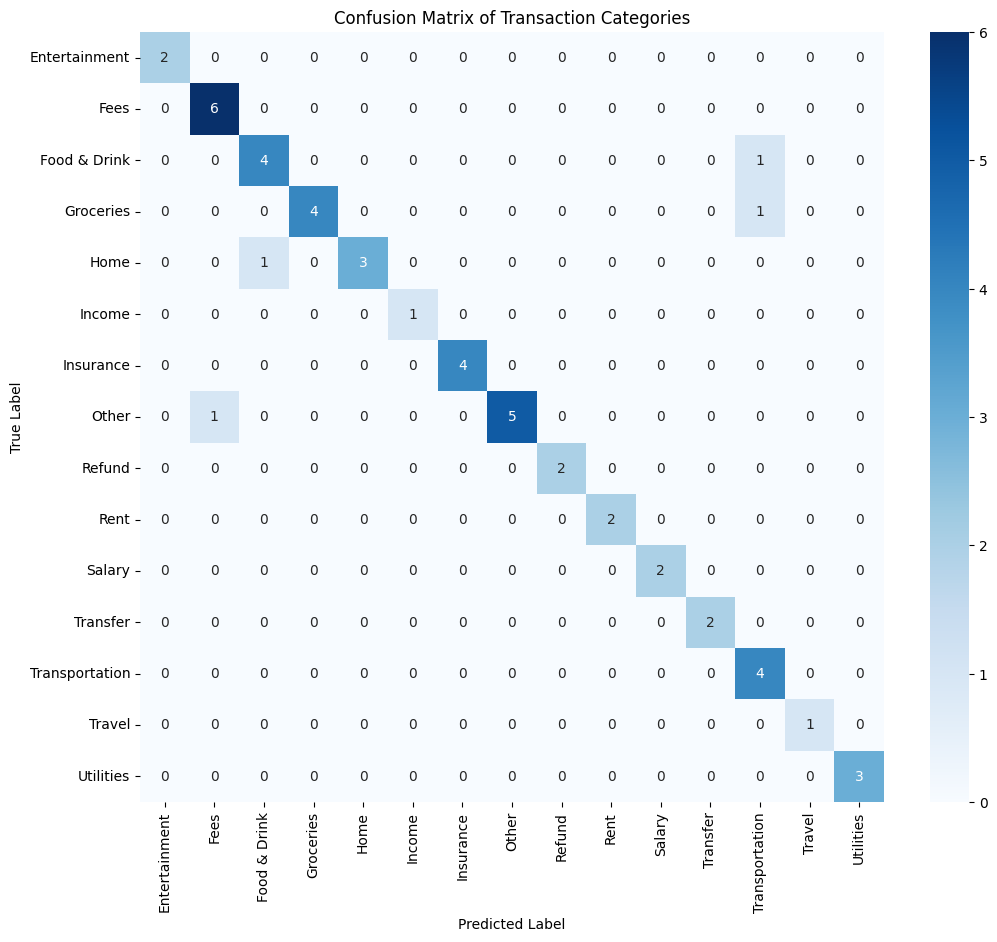

In [106]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Getting original category names from label_encoder
category_names_1 = label_encoder.classes_

# Creating the confusion matrix
cm_1 = confusion_matrix(y_test_1, y_pred_1)

# Plotting the confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues',
            xticklabels=category_names_1, yticklabels=category_names_1)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix of Transaction Categories')
plt.savefig('confusion_matrix.png', bbox_inches='tight') # Save before showing
plt.show()

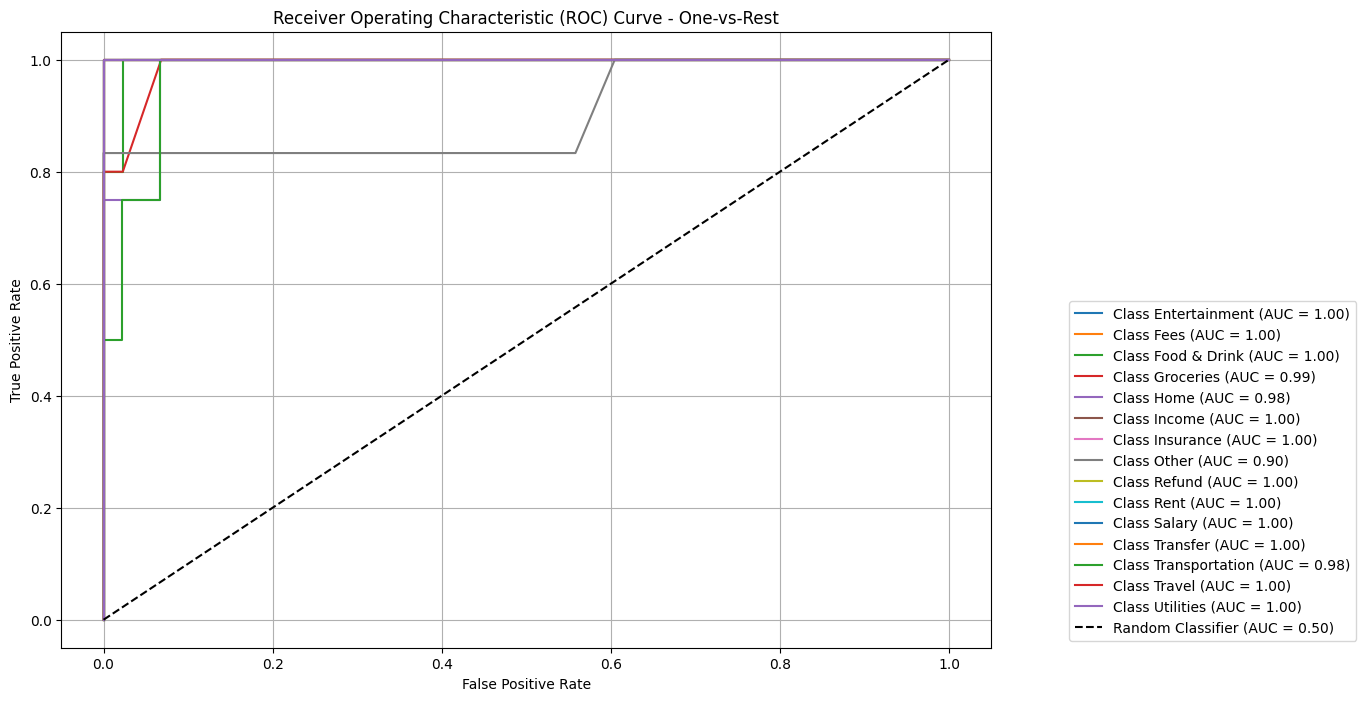

In [107]:
#creating ROC Curves
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Getting number of classes/categories
n_classes = len(category_names_1)

# Binarizing true labels for ROC curve
y_test_binarized = label_binarize(y_test_1, classes=range(n_classes))

# Getting predicted probabilities for each class from model
y_score = concept_model.predict_proba(X_test_1)

# Compute ROC curve and ROC area for each category
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plotting ROC curves for each class
plt.figure(figsize=(12, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {category_names_1[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - One-vs-Rest')
plt.legend(loc='lower right', bbox_to_anchor=(1.4, 0))
plt.grid(True)
plt.savefig('roc_curve.png', bbox_inches='tight')
plt.show()

# Large Model w/Focus on Text Data

In [2]:
#importing data
df_transactions = pd.read_parquet("/content/drive/MyDrive/Senior Year/Spring 2026/DSA 412/0000.parquet")
print(df_transactions.head())

  transaction_description              category    country currency
0                    Wage                Income        USA      USD
1    Arby's (Contactless)         Food & Dining  AUSTRALIA      AUD
2    Occupational Therapy  Healthcare & Medical        USA      USD
3   Potbelly Store Branch         Food & Dining         UK      GBP
4      Amazon - AUSTRALIA     Shopping & Retail  AUSTRALIA      AUD


In [3]:
#using USA transactions only
df_transactions_usa = df_transactions[df_transactions['country'] == 'USA']
print(df_transactions_usa.head())

   transaction_description              category country currency
0                     Wage                Income     USA      USD
2     Occupational Therapy  Healthcare & Medical     USA      USD
8                 Starlink  Utilities & Services     USA      USD
21    Retirement TXN109720    Financial Services     USA      USD
31            Chiropractor  Healthcare & Medical     USA      USD


## Preprocess/Data Exploration

In [4]:
#examining the data
df_transactions_usa.info()

print(df_transactions_usa.isnull().sum())

print(df_transactions_usa['category'].value_counts())

print(df_transactions_usa['transaction_description'].unique()[:5])

print(df_transactions_usa['currency'].value_counts())

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 899163 entries, 0 to 4501042
Data columns (total 4 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   transaction_description  899163 non-null  object
 1   category                 899163 non-null  object
 2   country                  899163 non-null  object
 3   currency                 899163 non-null  object
dtypes: object(4)
memory usage: 34.3+ MB

--- Missing Values ---
transaction_description    0
category                   0
country                    0
currency                   0
dtype: int64

--- Category Distribution (USA) ---
category
Shopping & Retail             90583
Utilities & Services          90423
Transportation                90115
Government & Legal            90085
Healthcare & Medical          90064
Charity & Donations           89934
Financial Services            89780
Food & Dining                 89576
Entertainment & Rec

## Text Preprocessing/TF-IDF Vectorization

In [5]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

# Download NLTK stop words if not already downloaded
try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

#cleaning/standardizing the text data
def clean_text(text):
    # Converting text to lowercase
    text = text.lower()
    # Removing punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Removing numerical digits
    text = re.sub(r'\d+', '', text)
    # Removing stop words
    text = ' '.join([word for word in text.split() if word not in stop_words])
    return text

#Cleaning transaction text data
df_transactions_usa['cleaned_description'] = df_transactions_usa['transaction_description'].apply(clean_text)

#checking to see if cleaning worked
print("Original vs Cleaned Description:")
print(df_transactions_usa[['transaction_description', 'cleaned_description']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Original vs Cleaned Description (First 5 rows):
   transaction_description   cleaned_description
0                     Wage                  wage
2     Occupational Therapy  occupational therapy
8                 Starlink              starlink
21    Retirement TXN109720        retirement txn
31            Chiropractor          chiropractor


/tmp/ipykernel_3447/1535034564.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_transactions_usa['cleaned_description'] = df_transactions_usa['transaction_description'].apply(clean_text)


In [7]:
#creating TF-IDF features with cleaned text data
tfidf_vectorizer = TfidfVectorizer(max_features=50000) # Limiting to 50000 features as an example
tfidf_features = tfidf_vectorizer.fit_transform(df_transactions_usa['cleaned_description'])

#examining features
print("Shape:", tfidf_features.shape)
print("First 5 unique features:")
print(tfidf_vectorizer.get_feature_names_out()[:5])

Shape of TF-IDF features matrix: (899163, 604)
First 5 unique features (words):
['accounting' 'ach' 'adidas' 'advisor' 'afternoon']


## Encoding Other Features

In [8]:
from sklearn.preprocessing import LabelEncoder

# Initializing LabelEncoder
label_encoder = LabelEncoder()

# Applying fit_transform to category column
df_transactions_usa['encoded_category'] = label_encoder.fit_transform(df_transactions_usa['category'])

# Print encoded numerical values for categories
print("--- Category Encoding Mapping ---")
for i, category in enumerate(label_encoder.classes_):
    print(f"{category}: {i}")

print("\n--- First 5 rows with Encoded Categories ---")
print(df_transactions_usa[['category', 'encoded_category']].head())

--- Category Encoding Mapping ---
Charity & Donations: 0
Entertainment & Recreation: 1
Financial Services: 2
Food & Dining: 3
Government & Legal: 4
Healthcare & Medical: 5
Income: 6
Shopping & Retail: 7
Transportation: 8
Utilities & Services: 9

--- First 5 rows with Encoded Categories ---
                category  encoded_category
0                 Income                 6
2   Healthcare & Medical                 5
8   Utilities & Services                 9
21    Financial Services                 2
31  Healthcare & Medical                 5


/tmp/ipykernel_3447/1716612489.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_transactions_usa['encoded_category'] = label_encoder.fit_transform(df_transactions_usa['category'])


## Combining the Features

In [38]:
#setting X and Y
X = tfidf_features
y = df_transactions_usa['encoded_category']

print(f"Shape of X (features): {X.shape}")
print(f"Shape of y (target): {y.shape}")

Shape of X (features): (899163, 604)
Shape of y (target): (899163,)


In [39]:
# setting train and test splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## XGBoost Model

In [37]:
#importing necessary packages/libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import xgboost
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, classification_report, ConfusionMatrixDisplay

from sklearn.model_selection import RandomizedSearchCV

In [41]:
#scaling data (only fitting on training data to prevent leakage)
scaler = StandardScaler(with_mean=False)
scaledX_train = scaler.fit_transform(X_train)
scaledX_test = scaler.transform(X_test)

In [46]:
from sklearn.model_selection import train_test_split

# Splitting training data to create validation set
X_train_sub, X_val_sub, y_train_sub, y_val_sub = train_test_split(
    scaledX_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

#initializing xgboost classifier
boost = XGBClassifier(
    n_estimators=50,  # Reduced number of estimators for faster training
    objective='multi:softmax',
    num_class=len(label_encoder.classes_),
    eval_metric='mlogloss', # Evaluation metric
    use_label_encoder=False,
    n_jobs=-1,  # Using all available cores for parallel processing
    random_state=23
)

#fitting model
print("Training XGBoost model...")
boost.fit(
    X_train_sub, y_train_sub,
    eval_set=[(X_val_sub, y_val_sub)] # Keeping eval_set for potential manual monitoring or if early_stopping_rounds becomes available
)
print("XGBoost model training complete.")

Training XGBoost model...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [03:57:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[0]	validation_0-mlogloss:2.03458
[1]	validation_0-mlogloss:1.89613
[2]	validation_0-mlogloss:1.77360
[3]	validation_0-mlogloss:1.64563
[4]	validation_0-mlogloss:1.52059
[5]	validation_0-mlogloss:1.41488
[6]	validation_0-mlogloss:1.33407
[7]	validation_0-mlogloss:1.27836
[8]	validation_0-mlogloss:1.24004
[9]	validation_0-mlogloss:1.20961
[10]	validation_0-mlogloss:1.18034
[11]	validation_0-mlogloss:1.15078
[12]	validation_0-mlogloss:1.12218
[13]	validation_0-mlogloss:1.09795
[14]	validation_0-mlogloss:1.07473
[15]	validation_0-mlogloss:1.05277
[16]	validation_0-mlogloss:1.03201
[17]	validation_0-mlogloss:1.01215
[18]	validation_0-mlogloss:0.99470
[19]	validation_0-mlogloss:0.97755
[20]	validation_0-mlogloss:0.96135
[21]	validation_0-mlogloss:0.94524
[22]	validation_0-mlogloss:0.93143
[23]	validation_0-mlogloss:0.91711
[24]	validation_0-mlogloss:0.90353
[25]	validation_0-mlogloss:0.89190
[26]	validation_0-mlogloss:0.87947
[27]	validation_0-mlogloss:0.86783
[28]	validation_0-mlogloss:0.8

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[45]	validation_0-mlogloss:0.72481
[46]	validation_0-mlogloss:0.71935
[47]	validation_0-mlogloss:0.71406
[48]	validation_0-mlogloss:0.70838
[49]	validation_0-mlogloss:0.70350
XGBoost model training complete.


In [49]:
# Making predictions on test set
y_pred_xgb = boost.predict(X_test)

# Calculating accuracy
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

# Calculating weighted recall
recall_xgb = recall_score(y_test, y_pred_xgb, average='weighted')

print(f"XGBoost Accuracy: {accuracy_xgb:.4f}")
print(f"XGBoost Recall (weighted): {recall_xgb:.4f}")

XGBoost Accuracy: 0.9611
XGBoost Recall (weighted): 0.9611


In [50]:
#looking at classification report
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     27077
           1       1.00      1.00      1.00     26787
           2       1.00      0.97      0.99     27234
           3       0.82      0.98      0.89     27044
           4       0.96      0.96      0.96     26889
           5       0.96      0.95      0.96     27087
           6       1.00      0.95      0.97     26574
           7       0.93      0.90      0.92     26940
           8       0.98      0.94      0.96     26951
           9       1.00      0.95      0.98     27166

    accuracy                           0.96    269749
   macro avg       0.96      0.96      0.96    269749
weighted avg       0.96      0.96      0.96    269749



## Naive Bayes Model

In [35]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, recall_score

# Initializing and training Multinomial Naive Bayes model
nb_model = MultinomialNB()
print("Training Multinomial Naive Bayes model...")
nb_model.fit(X_train, y_train)
print("Multinomial Naive Bayes model training complete.")

Training Multinomial Naive Bayes model...
Multinomial Naive Bayes model training complete.


In [36]:
# Making predictions on test set
y_pred_nb = nb_model.predict(X_test)

# Calculating accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

# Calculating weighted recall
recall_nb = recall_score(y_test, y_pred_nb, average='weighted')

print(f"Multinomial Naive Bayes Accuracy: {accuracy_nb:.4f}")
print(f"Multinomial Naive Bayes Recall (weighted): {recall_nb:.4f}")

Multinomial Naive Bayes Accuracy: 0.9830
Multinomial Naive Bayes Recall (weighted): 0.9830


## Random Forest Model

In [51]:
# splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# verifying the split
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (629414, 604)
Shape of X_test: (269749, 604)
Shape of y_train: (629414,)
Shape of y_test: (269749,)


In [55]:
from sklearn.ensemble import RandomForestClassifier

# Initializing random forest classifier for faster runtime
model_fast = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)

print("RandomForestClassifier initialized for faster training.")

RandomForestClassifier initialized for faster training.


In [56]:
#fitting model
model_fast.fit(X_train, y_train)

RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)

In [57]:
from sklearn.metrics import accuracy_score, recall_score

# Making predictions on the test set
y_pred = model_fast.predict(X_test)

# Calculating accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculating weighted recall
recall = recall_score(y_test, y_pred, average='weighted')

print(f"Accuracy: {accuracy:.4f}")
print(f"Recall (weighted): {recall:.4f}")

Accuracy: 0.9859
Recall (weighted): 0.9859


In [58]:
#looking at classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     27077
           1       1.00      1.00      1.00     26787
           2       1.00      1.00      1.00     27234
           3       0.99      0.99      0.99     27044
           4       0.98      0.98      0.98     26889
           5       0.96      0.98      0.97     27087
           6       0.98      0.99      0.99     26574
           7       0.96      0.94      0.95     26940
           8       0.99      0.99      0.99     26951
           9       0.99      1.00      0.99     27166

    accuracy                           0.99    269749
   macro avg       0.99      0.99      0.99    269749
weighted avg       0.99      0.99      0.99    269749



In [60]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score
import numpy as np
# Cross validating results to determine if there is extreme overfitting/
# poor generalization

# Initializing Stratified K-Fold cross-validator
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Storing metrics for each fold
fold_accuracies = []
fold_recalls = []

print("Starting K-Fold Cross-Validation...")

# Iterate over folds
for fold, (train_index, val_index) in enumerate(kf.split(X, y)):
    print(f"\n--- Fold {fold+1}/{kf.n_splits} ---")

    # Spliting data for current fold
    X_train_fold, X_val_fold = X[train_index], X[val_index]
    y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index] # Use iloc for Series indexing

    # Initizializing fresh model for each fold
    # using lower number of estimators to get idea of robustness without
    # extremely long runtimes
    fold_model = RandomForestClassifier(n_estimators=20, n_jobs=-1, random_state=42)

    # Training the model
    fold_model.fit(X_train_fold, y_train_fold)

    # Making predictions on validation set
    y_pred_fold = fold_model.predict(X_val_fold)

    # Calculating performance metrics
    accuracy_fold = accuracy_score(y_val_fold, y_pred_fold)
    recall_fold = recall_score(y_val_fold, y_pred_fold, average='weighted')

    fold_accuracies.append(accuracy_fold)
    fold_recalls.append(recall_fold)

    print(f"Fold Accuracy: {accuracy_fold:.4f}")
    print(f"Fold Recall (weighted): {recall_fold:.4f}")

# Overview of results with standard deviation
print("\n--- Cross-Validation Results ---")
print(f"Average Accuracy across {kf.n_splits} folds: {np.mean(fold_accuracies):.4f} (+/- {np.std(fold_accuracies):.4f})")
print(f"Average Recall (weighted) across {kf.n_splits} folds: {np.mean(fold_recalls):.4f} (+/- {np.std(fold_recalls):.4f})")

Starting K-Fold Cross-Validation...

--- Fold 1/5 ---


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fold Accuracy: 0.9850
Fold Recall (weighted): 0.9850

--- Fold 2/5 ---
Fold Accuracy: 0.9854
Fold Recall (weighted): 0.9854

--- Fold 3/5 ---
Fold Accuracy: 0.9855
Fold Recall (weighted): 0.9855

--- Fold 4/5 ---
Fold Accuracy: 0.9859
Fold Recall (weighted): 0.9859

--- Fold 5/5 ---
Fold Accuracy: 0.9856
Fold Recall (weighted): 0.9856

--- Cross-Validation Results ---
Average Accuracy across 5 folds: 0.9855 (+/- 0.0003)
Average Recall (weighted) across 5 folds: 0.9855 (+/- 0.0003)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Getting original category names from label_encoder
category_names = label_encoder.classes_

print("Libraries imported and category names retrieved:")
print(category_names)

Libraries imported and category names retrieved:
['Charity & Donations' 'Entertainment & Recreation' 'Financial Services'
 'Food & Dining' 'Government & Legal' 'Healthcare & Medical' 'Income'
 'Shopping & Retail' 'Transportation' 'Utilities & Services']


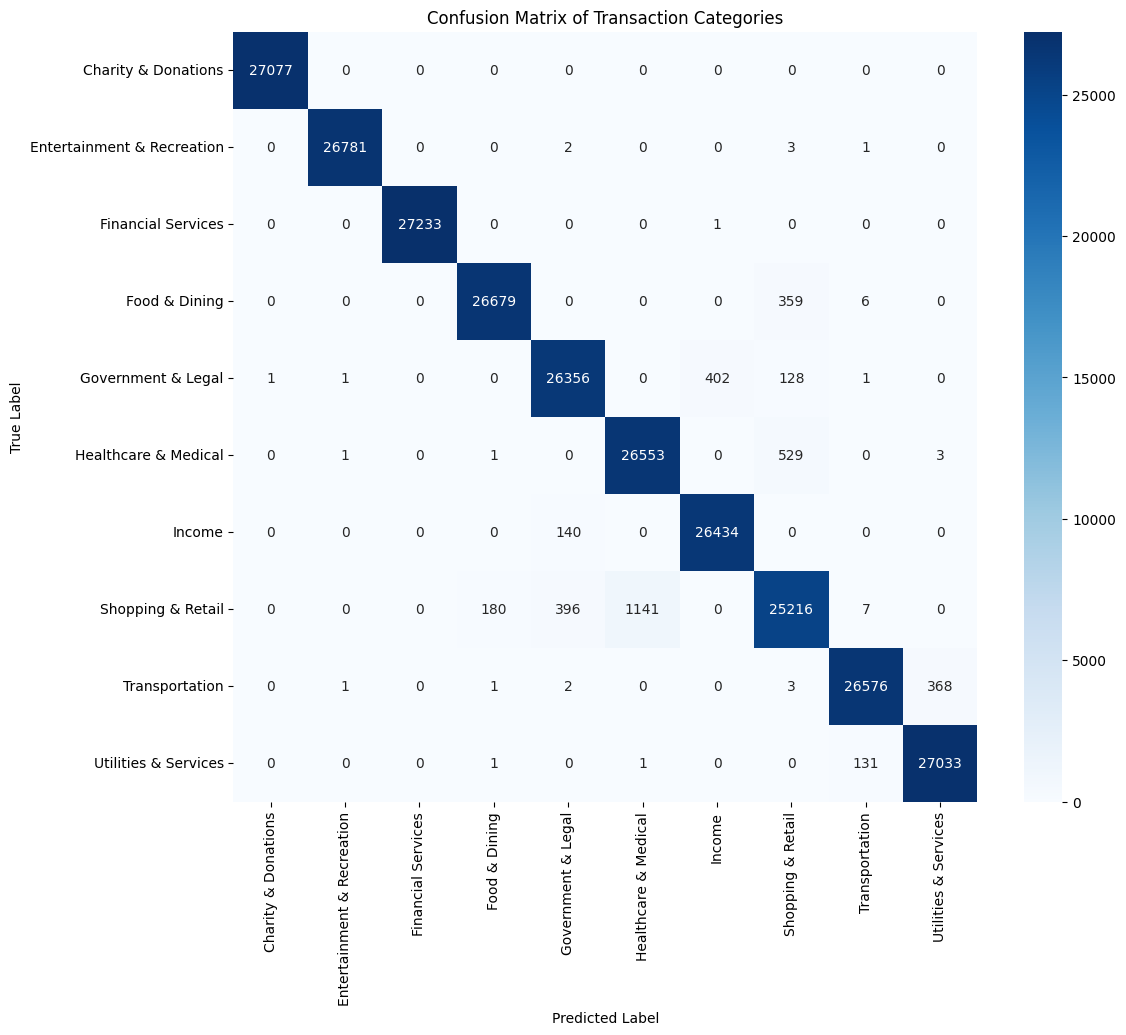

In [ ]:
from sklearn.metrics import confusion_matrix

# Creating the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plotting the confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=category_names, yticklabels=category_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix of Transaction Categories')
plt.show()
